# kNN 최근접 이웃 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week04/knn/lab/knn.ipynb)

가장 가까운 k 개의 다수결. 직접 구현하고, 실제 데이터에서 표준화와 차원의 저주를 확인한다.

- **파트 1**: kNN 직접 구현 (거리 · 정렬 · 다수결)
- **파트 2**: 와인 178병: 표준화 전후 비교
- **파트 3**: 교차 검증으로 k 고르기 + 잡음 특징 더하기

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

## 슬라이드의 예시 데이터

과일 21개의 (크기, 단맛). 마지막 귤 하나는 사과 무리 안에 잘못 적힌 점.

In [ ]:
# Same example as the slides: (size, sweetness) of 8 apples and 13 tangerines
X = np.array([[7.5, 3.5], [8.2, 4.5], [6.8, 3.0], [7.0, 5.2], [8.5, 3.2], [6.4, 4.0], [7.8, 5.5], [6.6, 5.4],   # apples
              [2.5, 7.5], [3.2, 8.4], [4.0, 6.8], [2.0, 6.0], [3.5, 5.8], [4.6, 7.6], [2.8, 4.9], [4.2, 8.8],
              [5.0, 6.5], [1.8, 8.0], [3.0, 7.0], [4.8, 5.6],                                                  # tangerines
              [6.1, 4.8]])                                                                                     # mislabeled tangerine
y = np.array(["apple"] * 8 + ["tangerine"] * 13)
q = np.array([6.0, 4.6])                                  # the new fruit
plt.scatter(X[:8, 0], X[:8, 1], label="apple"); plt.scatter(X[8:, 0], X[8:, 1], marker="s", label="tangerine")
plt.scatter(*q, marker="*", s=300, color="gold", edgecolor="k", label="new"); plt.xlabel("size"); plt.ylabel("sweetness"); plt.legend(); plt.show()

**예상 결과**

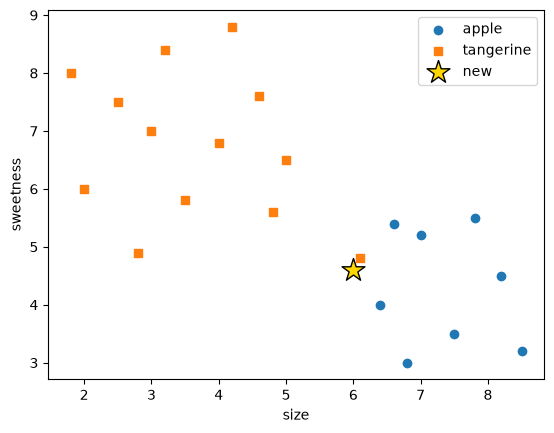

## 파트 1. kNN 직접 구현

$$d(\mathbf{x}, \mathbf{q}) = \sqrt{\sum_j (x_j - q_j)^2}$$

In [ ]:
def knn_predict(X, y, q, k):
    d = None  # TODO: Euclidean distance from q to every row of X
    nearest = None  # TODO: indices of the k smallest distances
    votes = Counter(y[nearest])
    return votes.most_common(1)[0][0], d[nearest].round(2)

for k in [1, 3, 21]:
    label, dists = knn_predict(X, y, q, k)
    print(f"k={k:2d}: {label:9s}  nearest distances {dists[:3]}")

**예상 결과**

```
k= 1: tangerine  nearest distances [0.22]
k= 3: apple      nearest distances [0.22 0.72 1.  ]
k=21: tangerine  nearest distances [0.22 0.72 1.  ]
```

In [ ]:
# Leave-one-out: hide one fruit, predict it from the other 20
def leave_one_out(X, y, k):
    correct = 0
    for i in range(len(X)):
        mask = np.arange(len(X)) != i
        correct += None  # TODO: 1 if the hidden fruit is predicted right
    return correct

for k in [1, 3, 5, 11, 15, 19]:
    print(f"k={k:2d}: {leave_one_out(X, y, k)}/21")

**예상 결과**

```
k= 1: 19/21
k= 3: 20/21
k= 5: 20/21
k=11: 20/21
k=15: 12/21
k=19: 13/21
```

## 파트 2. 실제 데이터: 와인 178병

이탈리아 같은 지역 와인 178병의 화학 성분 13가지로 품종(1, 2, 3) 을 맞힌다. 처음 실행하면 CSV 를 내려받는다. 특징마다 크기가 얼마나 다른지 먼저 보자.

In [ ]:
import pandas as pd
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"
cols = ["cultivar", "alcohol", "malic_acid", "ash", "alcalinity", "magnesium", "phenols", "flavanoids",
        "nonflavanoid", "proanthocyanins", "color", "hue", "od280", "proline"]
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/wine.csv"):
    import urllib.request; urllib.request.urlretrieve(url, "data/wine.csv")
df = pd.read_csv("data/wine.csv", header=None, names=cols)
print(df.shape); print(df.describe().loc[["min", "max"]].round(1).T)

**예상 결과**

```
(178, 14)
                   min     max
cultivar           1.0     3.0
alcohol           11.0    14.8
malic_acid         0.7     5.8
ash                1.4     3.2
alcalinity        10.6    30.0
magnesium         70.0   162.0
phenols            1.0     3.9
flavanoids         0.3     5.1
nonflavanoid       0.1     0.7
proanthocyanins    0.4     3.6
color              1.3    13.0
hue                0.5     1.7
od280              1.3     4.0
proline          278.0  1680.0
```

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

Xw, yw = df[cols[1:]].to_numpy(float), df["cultivar"].to_numpy()
folds = KFold(5, shuffle=True, random_state=0)
raw = KNeighborsClassifier(5)
scaled = None  # TODO: standardize, then kNN with k=5
print("raw     :", cross_val_score(raw, Xw, yw, cv=folds).mean().round(3))
print("scaled  :", cross_val_score(scaled, Xw, yw, cv=folds).mean().round(3))

**예상 결과**

```
raw     : 0.714
scaled  : 0.967
```

**관찰**: 표준화 전에는 어떤 특징이 거리를 혼자 정하고 있었을까? (위 min / max 표를 보자)

## 파트 3. k 고르기와 차원의 저주

In [ ]:
ks = [1, 3, 5, 7, 9, 15, 25, 51]
acc = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(k)), Xw, yw, cv=folds).mean() for k in ks]
plt.plot(ks, acc, "o-"); plt.xlabel("k"); plt.ylabel("5-fold CV accuracy"); plt.show()
print("best k:", ks[int(np.argmax(acc))], round(max(acc), 3))

**예상 결과**

```
best k: 7 0.978
```

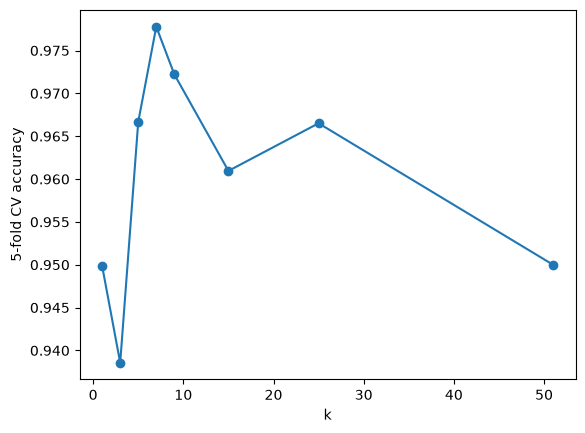

In [ ]:
# Add meaningless random features and watch accuracy fall
rng = np.random.default_rng(0)
for n_noise in [0, 10, 100, 1000]:
    Xn = None  # TODO: append n_noise random columns
    a = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), Xn, yw, cv=folds).mean()
    print(f"{n_noise:5d} noise features: {a:.3f}")

**예상 결과**

```
    0 noise features: 0.967
   10 noise features: 0.939
  100 noise features: 0.831
 1000 noise features: 0.567
```

**확인 질문**
1. 파트 1 에서 k=1 이 틀리는 이유를 슬라이드 그림으로 설명해 보자. leave-one-out 결과와 어떻게 연결되나?
2. 파트 2 에서 표준화 대신 `proline` 열 하나만 빼고 kNN 을 하면 정확도는 어떻게 될까? 직접 해 보자.
3. 파트 3 에서 잡음 특징이 1000개일 때 정확도는 찍기(약 40%) 와 비교해 어떤가?
4. (도전) 잡음 특징 1000개를 더한 데이터에 `sklearn.decomposition.PCA(n_components=10)` 을 먼저 적용하면 회복될까?

데이터 출처: Wine, UCI Machine Learning Repository (Forina et al., PARVUS).